In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from linearmodels import IV2SLS
from scipy import stats
import statsmodels.api as sm
df = pd.read_csv("data/cars.csv")

# Problem 1 - Indledende analyse

#### 1A)

,mean,std,10%,50%,90%
Pris ($10.000),36.048,17.127,18.665,31.820,59.680
Markedsandel (%),0.142,0.210,0.004,0.064,0.368
Hestekræfter,192.182,83.882,94.000,175.000,303.000
MPG,20.936,6.583,15.000,19.000,28.000
Footprint,13392.630,1968.915,11020.111,13330.064,15958.000
Vægt,3561.211,897.766,2465.000,3470.500,4733.000


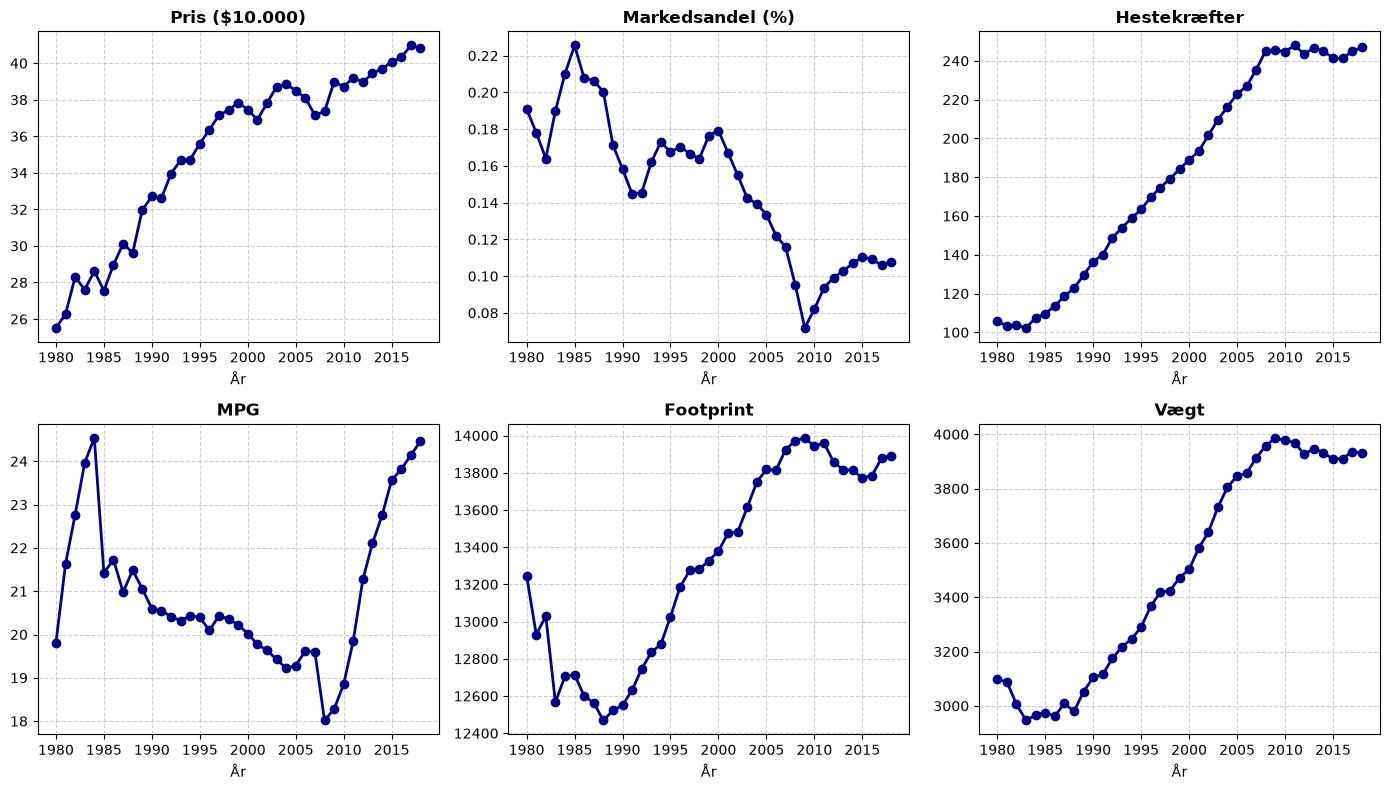

In [43]:
# Deskriptiv statistik for priser, markedsandele og produktegenskaber
df['market_share_pct'] = 100 * df['market_share']
desc_vars = ['price', 'market_share_pct', 'hp', 'mpg', 'footprint', 'weight']
descriptive = df[desc_vars].describe(percentiles=[0.1, 0.5, 0.9]).T
descriptive.index = ['Pris ($10.000)', 'Markedsandel (%)', 'Hestekræfter', 'MPG', 
                    'Footprint', 'Vægt']
display(descriptive[['mean', 'std', '10%', '50%', '90%']].round(3))

# Vis udviklingen over tid i priser, markedsandele og andre produktegenskaber
# Gennemsnit pr. år for desc_vars
yearly = df.groupby('year')[desc_vars].mean()


fig, axes = plt.subplots(2, 3, figsize=(14,8))
axes = axes.flatten()

titles = ['Pris ($10.000)', 'Markedsandel (%)', 'Hestekræfter', 'MPG', 'Footprint', 'Vægt']

#3. plot
for i, var in enumerate(desc_vars):
    axes[i].plot(yearly.index, yearly[var], marker='o', color='navy', linewidth=2)
    axes[i].set_title(titles[i], fontweight='bold')
    axes[i].set_xlabel('År')
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()



#### 1B)

In [76]:
# Specifikation 1
df['const'] = 1

S1 = sm.OLS(df['dlogS'], df[['const','price']]).fit(cov_type='HC1')

# Specifikation 2
Xkon = ['hp','mpg','height','footprint','weight','number_trims']
Xdummy = ['releaseYear','yearsSinceDesign','sport','EV','truck','suv','van']
Xvar = Xkon + Xdummy

exog_vars2 = ['const'] + Xvar + ['price']
S2 = sm.OLS(df['dlogS'], df[exog_vars2]).fit(cov_type='HC1')

# Specifikation 3
# Tilføjer årsdummies
year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
# Store year variable names for later use
years = list(year_dummies.columns) # ['y_1981', 'y_1982', ...]


exog_vars3 = exog_vars2 + years
S3 = sm.OLS(df['dlogS'], df[exog_vars3]).fit(cov_type='HC1')

# Specifikation 4
for var in Xkon:
    df[f'{var}_log'] = np.log(df[var])

Xkon_log = [f'{var}_log' for var in Xkon]

exog_vars4 = ['const'] + Xkon_log + Xdummy + ['price'] + years

S4 = sm.OLS(df['dlogS'], df[exog_vars4]).fit(cov_type='HC1')

models = [S1,S2,S3,S4]
model_names = ['Specifikation 1', 'Specifikation 2', 'Specifikation 3', 'Specifikation 4']

results = pd.DataFrame({
    'alpha_hat': [m.params['price'] for m in models],
    'SE(alpha_hat)': [m.bse['price'] for m in models],
    'R2': [m.rsquared for m in models],
    'TSS': [m.centered_tss for m in models],
    'ESS': [m.ess for m in models],
    'RSS': [m.ssr for m in models],
    'Produktkarakteristika': ['Nej', 'Ja', 'Ja', 'Ja (log)'],
    'Type-dummies': ['Nej', 'Ja', 'Ja', 'Ja'],
    'Års-dummies': ['Nej', 'Nej', 'Ja', 'Ja']
}, index=[f'Model {i}' for i in range(1, len(models) + 1)])

display(results.round(4))

,alpha_hat,SE(alpha_hat),R2,TSS,ESS,RSS,Produktkarakteristika,Type-dummies,Års-dummies
Model 1,-0.0373,0.0010,0.1062,37300.6952,3961.2203,33339.4749,Nej,Nej,Nej
Model 2,-0.0243,0.0016,0.3001,37300.6952,11192.3322,26108.3630,Ja,Ja,Nej
Model 3,-0.0370,0.0017,0.3410,37300.6952,12720.2260,24580.4692,Ja,Ja,Ja
Model 4,-0.0298,0.0014,0.5065,37300.6952,18893.6537,18407.0415,Ja (log),Ja,Ja


# Problem 2

# Problem 4 - Monte Carlo simulation

In [ ]:
def simulate(gamma0,gamma1,gamma2):
    #definer parameter værdier
    n = 500 
    beta0 = 0.5
    beta1 = -0.1
    z = np.random.normal(loc = 0, scale = 1, size = n)
    xi = np.random.normal(loc = 0, scale = 1, size = n)
    v = np.random.normal(loc = 0, scale = 1, size = n)
    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)
    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u 
    y = beta0 + beta1*p + xi

    # Opretter dataframe med estimeret værdier
    df = pd.DataFrame({
        'y': y,
        'z': z,
        'p': p
    })
    # Estimere med OLS
    result_OLS = smf.ols('y ~ p', data = df).fit()
    beta1_OLS = result_OLS.params['p']

    # Estimere modellen med IV2SLS, z bruges som instrument for p 

    result_IV = IV2SLS.from_formula('y ~ 1 + [p ~ z]', data = df).fit()
    beta1_IV = result_IV.params['p']
    return beta1_OLS, beta1_IV

def monte_carlo(reps=500):
    np.random.seed(0)
    #Gemmer OLS resultater
    OLS_result_S1 =[]
    OLS_result_S2 =[]
    OLS_result_S3 =[]
    #Gemmer IV resultater
    IV_result_S1 = []
    IV_result_S2 = []
    IV_result_S3 = []
    for r in range(reps):
        beta1_OLS_S1, beta1_IV_S1 = simulate(gamma0=0.25,gamma1=1,gamma2=1) # S1
        beta1_OLS_S2, beta1_IV_S2 = simulate(gamma0=0.25,gamma1=1,gamma2=0.25) # S2
        beta1_OLS_S3, beta1_IV_S3 = simulate(gamma0=0.25,gamma1=0.25,gamma2=1) # S3
        #Tilføj resultater til liste
        IV_result_S1.append(beta1_IV_S1)
        IV_result_S2.append(beta1_IV_S2)
        IV_result_S3.append(beta1_IV_S3)
        OLS_result_S1.append(beta1_OLS_S1)
        OLS_result_S2.append(beta1_OLS_S2)
        OLS_result_S3.append(beta1_OLS_S3)



    results = pd.DataFrame({'beta1_IV_S1': IV_result_S1,
                            'beta1_OLS_S1': OLS_result_S1,
                            'beta1_IV_S2': IV_result_S2,
                            'beta1_OLS_S2': OLS_result_S2,
                            'beta1_IV_S3': IV_result_S3,
                            'beta1_OLS_S3': OLS_result_S3,
                            })

    return results


results1 = monte_carlo()

In [ ]:
# Beregner bias og varians for estimatorne
beta1_true = -0.1
bias = results1.mean() - beta1_true
varians = results1.var()

bias_varians = pd.DataFrame({
    'Bias': bias,
    'Varians': varians
})




print(bias_varians)

                  Bias   Varians
beta1_IV_S1  -0.000081  0.002395
beta1_OLS_S1  0.368325  0.000515
beta1_IV_S2  -0.053499  0.056139
beta1_OLS_S2  0.532897  0.000611
beta1_IV_S3  -0.000063  0.000257
beta1_OLS_S3  0.116365  0.000052
